# Card 26 - Métricas e validação de modelos

Replica os exemplos das aulas no dataset Breast Cancer (sklearn): matriz de confusão, precisão/recall,
curva ROC, escolha do *cutoff*, árvore vs random forest e SHAP num `LinearSVC`.

> O conjunto de **teste só é usado para o resultado final**. Escolhas (qual modelo, qual cutoff) são feitas
> com validação cruzada no treino, senão o teste deixa de ser dado novo.

In [1]:
!pip install scikit-learn shap pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.stats import spearmanr
from sklearn import metrics
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)  # o KernelExplainer do shap usa o sorteio global do numpy

/home/edryck/Documentos/BootCamp/III - Aprendizado de Máquina Aplicado/Card 26 - Métricas e Validação de Modelos de Aprendizado de Máquina /Pratica/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dados

No dataset original 0 = maligno e 1 = benigno. O evento que interessa é o maligno, então eu inverto: assim o *recall* passa a medir "quantos tumores malignos eu peguei".

In [16]:
data = load_breast_cancer()
X = data.data
y = 1 - data.target   # 1 = maligno (evento de interesse), 0 = benigno

# stratify mantém a mesma proporção de malignos no treino e no teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("treino:", X_train.shape, "| teste:", X_test.shape)
print("proporção de malignos no teste: %.3f" % y_test.mean())

treino: (455, 30) | teste: (114, 30)
proporção de malignos no teste: 0.368


## Métricas a partir da matriz de confusão

Uma função só: dado o rótulo verdadeiro, a probabilidade e o corte, devolve a matriz e as 4 métricas.

In [18]:
def summarize(y_true, prob, cutoff=0.5):
    pred = (prob >= cutoff).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, pred).ravel()
    return {
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "accuracy": (tp + tn) / (tp + tn + fp + fn),
        "precision": tp / (tp + fp) if (tp + fp) else float("nan"), # do que eu previ, quanto era de fato
        "recall": tp / (tp + fn), # do que existia, quanto eu peguei
        "specificity": tn / (tn + fp), # o recall da outra classe
    }

## Árvore sem limite vs random forest

A árvore sem limite de profundidade é a candidata a decorar o treino. A forest usa 350 árvores com `min_samples_leaf=5`.
A AUC em validação cruzada é calculada **só no treino** (o teste fica guardado).

In [20]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
forest = RandomForestClassifier(
    n_estimators=350, min_samples_leaf=5, n_jobs=-1, random_state=SEED
).fit(X_train, y_train)

models = {"decision_tree": tree, "random_forest": forest}
rows = {}
for name, model in models.items():
    p_train = model.predict_proba(X_train)[:, 1]
    p_test = model.predict_proba(X_test)[:, 1]
    row = summarize(y_test, p_test)
    row["auc_train"] = metrics.roc_auc_score(y_train, p_train)
    row["auc_test"] = metrics.roc_auc_score(y_test, p_test)
    # validação cruzada só com o treino: é com ela que se compara os modelos
    row["auc_cv5_train"] = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc").mean()
    rows[name] = row

pd.DataFrame(rows).round(3)

,decision_tree,random_forest
TN,68.000,72.000
FP,4.000,0.000
FN,4.000,3.000
TP,38.000,39.000
accuracy,0.930,0.974
precision,0.905,1.000
recall,0.905,0.929
specificity,0.944,1.000
auc_train,1.000,0.998
auc_test,0.925,0.994


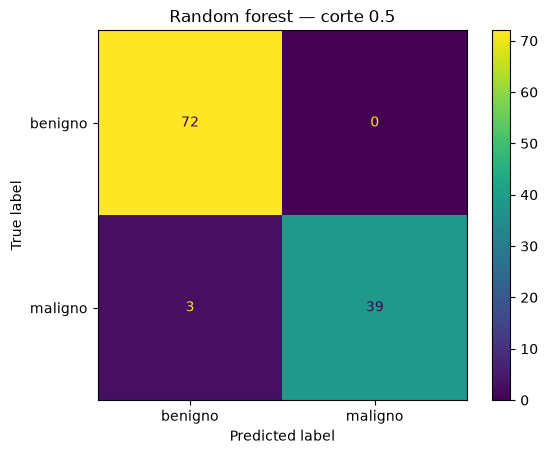

In [21]:
# matriz de confusão da forest no corte 0.5
p_forest = forest.predict_proba(X_test)[:, 1]
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, (p_forest >= 0.5).astype(int), display_labels=["benigno", "maligno"]
)
plt.title("Random forest — corte 0.5")
plt.show()

## Escolhendo o cutoff (sem olhar o teste)

O modelo é o mesmo, só muda onde eu corto a probabilidade. Para escolher o corte uso probabilidades **fora da dobra**
(`cross_val_predict`): cada exemplo do treino é previsto por um modelo que não o viu.
Regra de negócio do exemplo: pegar pelo menos 95% dos malignos (*recall* >= 0.95) com a maior precisão possível.

In [22]:
# probabilidade de cada exemplo do treino, prevista por um modelo que não treinou com ele
p_oof = cross_val_predict(forest, X_train, y_train, cv=5, method="predict_proba")[:, 1]

cutoffs = np.round(np.arange(0.05, 0.96, 0.05), 2)
sweep = pd.DataFrame({c: summarize(y_train, p_oof, c) for c in cutoffs}).T
sweep[["FP", "FN", "precision", "recall", "accuracy"]].round(3)

,FP,FN,precision,recall,accuracy
0.05,81.0,2.0,0.675,0.988,0.818
0.10,61.0,3.0,0.732,0.982,0.859
0.15,44.0,3.0,0.791,0.982,0.897
0.20,31.0,4.0,0.843,0.976,0.923
0.25,29.0,5.0,0.851,0.971,0.925
0.30,24.0,6.0,0.872,0.965,0.934
0.35,19.0,7.0,0.896,0.959,0.943
0.40,12.0,8.0,0.931,0.953,0.956
0.45,9.0,10.0,0.947,0.941,0.958
0.50,8.0,12.0,0.952,0.929,0.956


In [23]:
# regra: recall >= 0.95; entre os que atendem, maior precisão; empate fica com o corte maior
ok = sweep[sweep["recall"] >= 0.95]
best_cutoff = ok.sort_values(["precision"], ascending=False).query("precision == precision.max()").index.max()
print("cutoff escolhido na validação cruzada:", best_cutoff)

cutoff escolhido na validação cruzada: 0.4


In [25]:
# agora sim o teste, uma vez só, com o corte escolhido (e o 0.5 pra comparar)
pd.DataFrame({c: summarize(y_test, p_forest, c) for c in [0.5, best_cutoff]}).T.round(3)

,TN,FP,FN,TP,accuracy,precision,recall,specificity
0.5,72.0,0.0,3.0,39.0,0.974,1.000,0.929,1.000
0.4,71.0,1.0,3.0,39.0,0.965,0.975,0.929,0.986


## Curva ROC

A ROC varre todos os cortes: eixo Y = sensibilidade (recall), eixo X = 1 − especificidade.

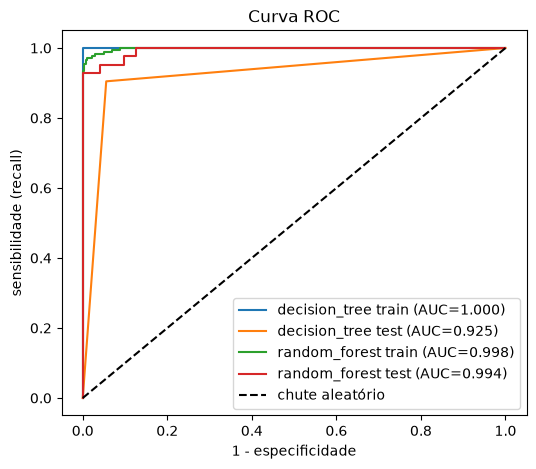

In [26]:
plt.figure(figsize=(6, 5))
for name, model in models.items():
    for split, (X_s, y_s) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        prob = model.predict_proba(X_s)[:, 1]
        fpr, tpr, thresholds = metrics.roc_curve(y_s, prob)   # os 3 vetores: fpr, tpr e cada corte
        auc = metrics.roc_auc_score(y_s, prob)
        plt.plot(fpr, tpr, label="%s %s (AUC=%.3f)" % (name, split, auc))

plt.plot([0, 1], [0, 1], "k--", label="chute aleatório")
plt.xlabel("1 - especificidade")
plt.ylabel("sensibilidade (recall)")
plt.title("Curva ROC")
plt.legend()
plt.show()

## SHAP num modelo que não se explica sozinho

O SVM só devolve a classe (ou a distância até a fronteira). O `KernelExplainer` funciona com qualquer modelo;
o `shap.kmeans` resume o treino em 10 centróides para acelerar. Explico a `decision_function` (contínua) em vez do `predict` (0/1), que dá valores bem mais grosseiros.

O SVM entra num pipeline com `StandardScaler`. Sem isso as variáveis de escala grande (área, perímetro) dominam o modelo
e a "importância" só reflete a escala dos dados, além de variar entre versões das bibliotecas.

In [27]:
svc = make_pipeline(StandardScaler(), LinearSVC(max_iter=20000, random_state=SEED)).fit(X_train, y_train)
print("acurácia do SVC no teste: %.3f" % svc.score(X_test, y_test))

background = shap.kmeans(X_train, 10)
explainer = shap.KernelExplainer(svc.decision_function, background)

sample = X_test[:40]   # 40 exemplos pra não demorar
shap_values = explainer.shap_values(sample, silent=True)

acurácia do SVC no teste: 0.965


/tmp/ipykernel_2499334/1311946378.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample, feature_names=data.feature_names)


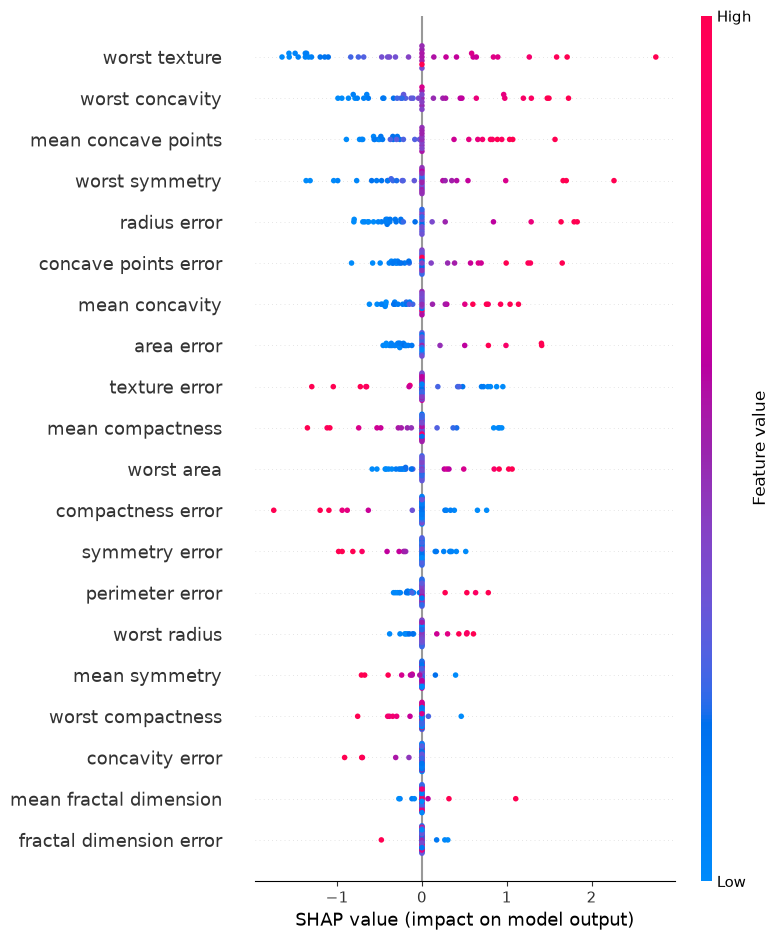

In [28]:
# visão global: quais variáveis mais pesam e em que direção (cor = valor da variável)
shap.summary_plot(shap_values, sample, feature_names=data.feature_names)

In [29]:
# importância = média do valor absoluto do SHAP por variável
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=data.feature_names)
importance.sort_values(ascending=False).head(10)

worst texture           0.841490
worst concavity         0.529675
mean concave points     0.459232
worst symmetry          0.447153
radius error            0.445447
concave points error    0.336666
mean concavity          0.306609
area error              0.291958
texture error           0.276199
mean compactness        0.267231
dtype: float64

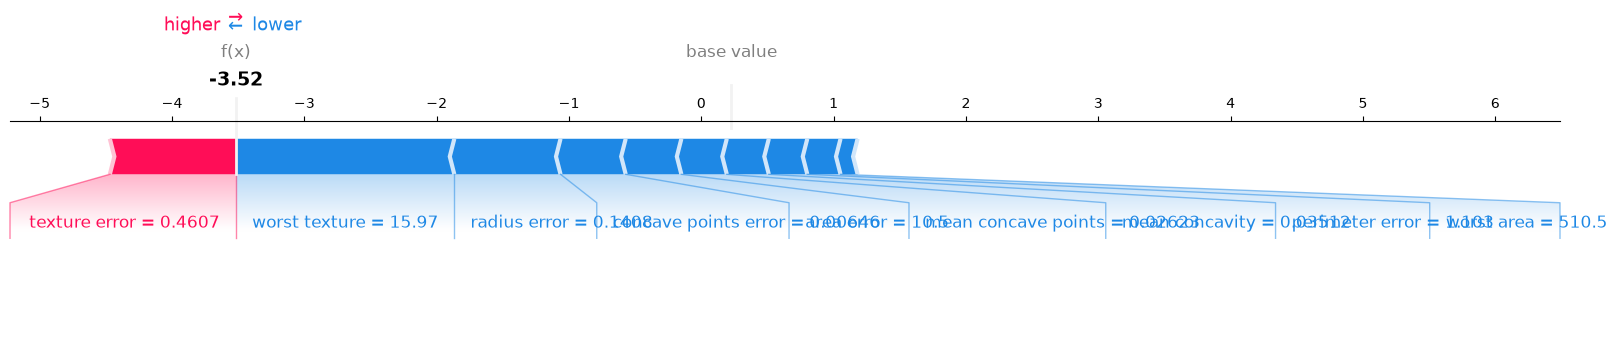

In [30]:
# visão individual: como cada variável empurrou a predição do exemplo 0
shap.force_plot(
    explainer.expected_value, shap_values[0], sample[0],
    feature_names=data.feature_names, matplotlib=True,
)

### Conferindo o SHAP

1. **Aditividade:** valor base + soma das contribuições tem que dar a saída do modelo.
2. **Valor exato:** em modelo linear o SHAP da variável j é `coef_j × (x_j − média_j)`. O `KernelExplainer` só aproxima isso
   (usa 10 centróides no lugar da média), então o ranking deve ser **parecido**, não idêntico.

In [31]:
base = float(np.ravel(explainer.expected_value)[0])
print("base + soma dos SHAP: %.4f" % (base + shap_values[0].sum()))
print("saída real do modelo : %.4f" % svc.decision_function(sample[:1])[0])

# coeficientes no espaço original dos dados (o pipeline divide pelo desvio-padrão antes do SVM)
coef = svc[-1].coef_[0] / svc[0].scale_
exact = pd.Series(np.abs(coef * (sample - X_train.mean(axis=0))).mean(axis=0), index=data.feature_names)

print("\ncorrelação de Spearman (SHAP vs exato): %.3f" % spearmanr(importance, exact)[0])
top_shap = set(importance.sort_values(ascending=False).head(5).index)
top_exact = set(exact.sort_values(ascending=False).head(5).index)
print("variáveis em comum no top 5:", len(top_shap & top_exact), "de 5")

base + soma dos SHAP: -3.5162
saída real do modelo : -3.5162

correlação de Spearman (SHAP vs exato): 0.980
variáveis em comum no top 5: 5 de 5
